# Lab 6 : Covariance, Correlation & Principal Component Analysis
**Lakshay** : AP24110010677 : B.Tech CSE (AI/ML)

**Question 1** : Compute covariance and correlation between a pair of attributes; compute the covariance matrix and the correlation matrix.

**Question 2** : Principal Component Analysis (PCA).

**Dataset** : a small **randomly generated** dataset of 10 students with 4 attributes, created with NumPy (random seed **77**, the last two digits of my roll number).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(77)            # last two digits of roll number

## Creating the random dataset
* `study_hours` : random whole number from 1 to 10
* `phone_hours` : goes **down** when study hours go up (+ a little randomness)
* `sleep_hours` : random whole number from 5 to 9 (not linked to anything)
* `marks` : goes **up** with study hours (+ a little randomness)

In [2]:
n = 10
study_hours = np.random.randint(1, 11, n)
phone_hours = np.clip(10 - study_hours + np.random.randint(-1, 2, n), 0, None)
sleep_hours = np.random.randint(5, 10, n)
marks = np.clip(8 * study_hours + 15 + np.random.randint(-6, 7, n), 0, 100)

df = pd.DataFrame({"study_hours": study_hours,
                   "phone_hours": phone_hours,
                   "sleep_hours": sleep_hours,
                   "marks": marks})
df

,study_hours,phone_hours,sleep_hours,marks
0,8,1,6,77
1,5,6,6,52
2,5,4,9,58
3,6,5,5,69
4,9,0,9,81
5,1,9,6,29
6,10,1,5,97
7,8,3,6,82
8,6,4,7,62
9,4,7,8,52


---
# Question 1 : Covariance & Correlation

### Theory
**Covariance** shows the *direction* in which two attributes change together.

$$\text{Cov}(X,Y) = \frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})$$

* Positive : both increase together · Negative : one goes up, the other goes down · ≈ 0 : no linear relationship
* It depends on the units, so it shows direction but **not strength**.

**Correlation (Pearson)** divides covariance by both standard deviations, so it has no units and always lies between **-1 and +1**.

$$r_{XY} = \frac{\text{Cov}(X,Y)}{\sigma_X\,\sigma_Y}$$

**Covariance matrix** : covariance of every pair of attributes (the diagonal holds the variances).
**Correlation matrix** : correlation of every pair of attributes (the diagonal is always 1).

| | Covariance | Correlation |
|---|---|---|
| Range | −∞ to +∞ | −1 to +1 |
| Units | depends on data | no units |
| Tells | direction only | direction **and** strength |

### Part A : Covariance & correlation between a pair of attributes
Pair chosen : **study_hours** and **marks**. First step by step using the formula, then with NumPy to check.

In [3]:
X = df["study_hours"]
Y = df["marks"]

step = pd.DataFrame({"x": X, "y": Y,
                     "x - x̄": X - X.mean(),
                     "y - ȳ": Y - Y.mean(),
                     "(x - x̄)(y - ȳ)": (X - X.mean()) * (Y - Y.mean())})
print(step)
print(f"\nx̄ = {X.mean()},  ȳ = {Y.mean()}")
print(f"Σ(x - x̄)(y - ȳ) = {step['(x - x̄)(y - ȳ)'].sum():.2f}")

    x   y  x - x̄  y - ȳ  (x - x̄)(y - ȳ)
0   8  77     1.8   11.1            19.98
1   5  52    -1.2  -13.9            16.68
2   5  58    -1.2   -7.9             9.48
3   6  69    -0.2    3.1            -0.62
4   9  81     2.8   15.1            42.28
5   1  29    -5.2  -36.9           191.88
6  10  97     3.8   31.1           118.18
7   8  82     1.8   16.1            28.98
8   6  62    -0.2   -3.9             0.78
9   4  52    -2.2  -13.9            30.58

x̄ = 6.2,  ȳ = 65.9
Σ(x - x̄)(y - ȳ) = 458.20


In [4]:
cov_xy = step["(x - x̄)(y - ȳ)"].sum() / (n - 1)
r_xy = cov_xy / (X.std() * Y.std())

print(f"Covariance  (formula) = {cov_xy:.4f}  |  np.cov      = {np.cov(X, Y)[0, 1]:.4f}")
print(f"Correlation (formula) = {r_xy:.4f}  |  np.corrcoef = {np.corrcoef(X, Y)[0, 1]:.4f}")

Covariance  (formula) = 50.9111  |  np.cov      = 50.9111
Correlation (formula) = 0.9835  |  np.corrcoef = 0.9835


In [5]:
for a, b in [("study_hours", "phone_hours"), ("sleep_hours", "marks")]:
    print(f"{a} vs {b} : covariance = {df[a].cov(df[b]):.4f},  correlation = {df[a].corr(df[b]):.4f}")

study_hours vs phone_hours : covariance = -7.2222,  correlation = -0.9475
sleep_hours vs marks : covariance = -4.9222,  correlation = -0.1691


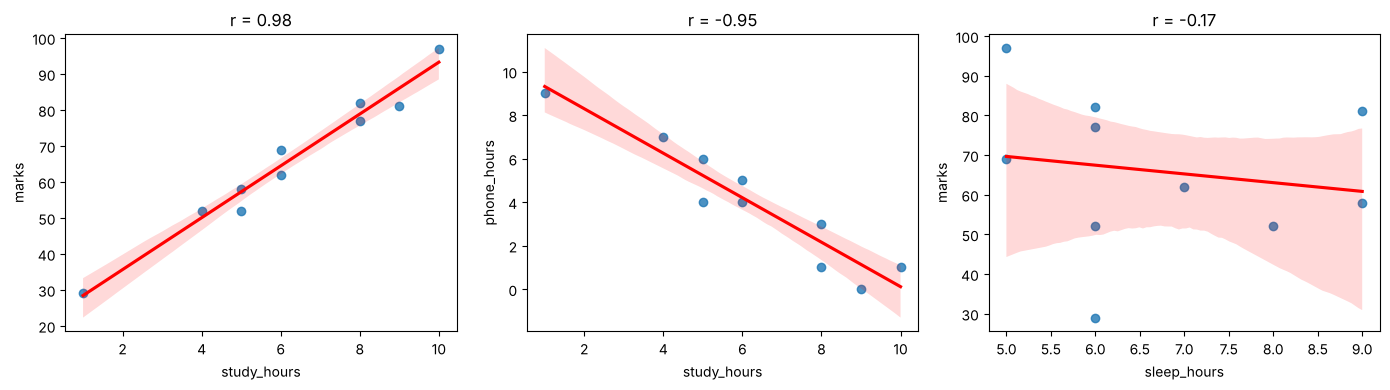

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (a, b) in zip(axes, [("study_hours", "marks"), ("study_hours", "phone_hours"), ("sleep_hours", "marks")]):
    sns.regplot(data=df, x=a, y=b, ax=ax, line_kws={"color": "red"})
    ax.set_title(f"r = {df[a].corr(df[b]):.2f}")
plt.tight_layout()
plt.show()

**Observation**
* study_hours vs marks : strong **positive** correlation.
* study_hours vs phone_hours : strong **negative** correlation.
* sleep_hours vs marks : weak correlation : no clear linear relationship.

### Part B : Covariance matrix

In [7]:
cov_matrix = df.cov()          # same as np.cov(df.values, rowvar=False)
cov_matrix

,study_hours,phone_hours,sleep_hours,marks
study_hours,7.066667,-7.222222,-0.377778,50.911111
phone_hours,-7.222222,8.222222,-0.444444,-50.444444
sleep_hours,-0.377778,-0.444444,2.233333,-4.922222
marks,50.911111,-50.444444,-4.922222,379.211111


### Part C : Correlation matrix

In [8]:
corr_matrix = df.corr()        # same as np.corrcoef(df.values, rowvar=False)
corr_matrix

,study_hours,phone_hours,sleep_hours,marks
study_hours,1.000000,-0.947478,-0.095094,0.983478
phone_hours,-0.947478,1.000000,-0.103716,-0.903396
sleep_hours,-0.095094,-0.103716,1.000000,-0.169139
marks,0.983478,-0.903396,-0.169139,1.000000


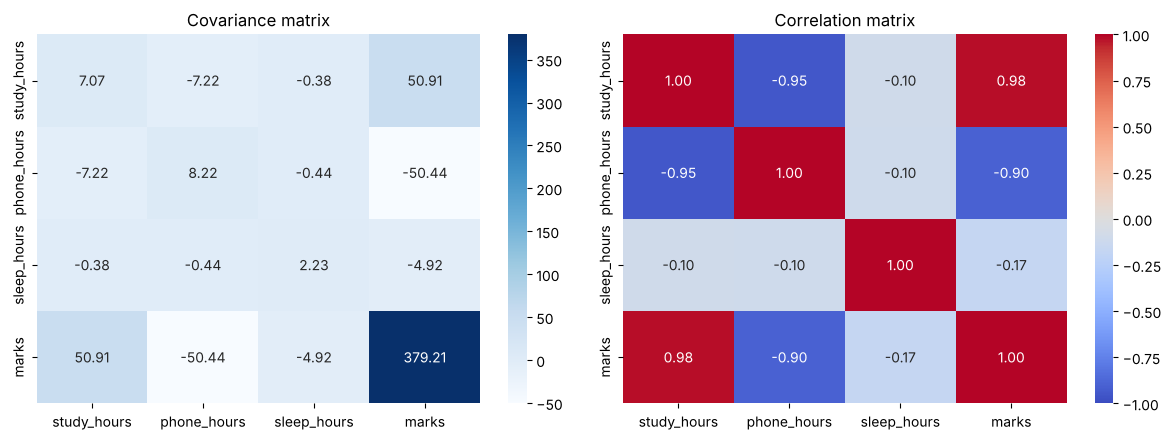

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(cov_matrix, annot=True, fmt=".2f", cmap="Blues", ax=axes[0])
axes[0].set_title("Covariance matrix")
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Correlation matrix")
plt.tight_layout()
plt.show()

### Result (Question 1)
* The covariance and correlation of a pair of attributes were calculated with the formula and matched NumPy's answers.
* The covariance matrix and correlation matrix of all 4 attributes were computed and shown as heatmaps.
* Covariance values depend on units (marks has a large variance), while correlation is always between -1 and +1, so correlation is easier to compare.

---
# Question 2 : Principal Component Analysis (PCA)

### Theory
PCA reduces the number of attributes by creating new ones, called **principal components (PCs)**, that capture as much of the data's variation as possible.

**Steps**
1. **Standardise** the data (mean 0, std 1).
2. Find the **covariance matrix**.
3. Find its **eigenvalues and eigenvectors**.
4. **Sort** them from largest to smallest eigenvalue (bigger eigenvalue = more variation captured).
5. Keep the top **k** eigenvectors and **project** the data onto them : Z = X · W.

Here we reduce **4 attributes → 2 principal components**.

### Step 1 : Standardise the data

In [10]:
X = df.values
X_std = (X - X.mean(axis=0)) / X.std(axis=0)
pd.DataFrame(X_std, columns=df.columns).round(3)

,study_hours,phone_hours,sleep_hours,marks
0,0.714,-1.103,-0.494,0.601
1,-0.476,0.735,-0.494,-0.752
2,-0.476,0.000,1.622,-0.428
3,-0.079,0.368,-1.199,0.168
4,1.110,-1.470,1.622,0.817
5,-2.062,1.838,-0.494,-1.997
6,1.507,-1.103,-1.199,1.683
7,0.714,-0.368,-0.494,0.871
8,-0.079,0.000,0.212,-0.211
9,-0.872,1.103,0.917,-0.752


### Step 2 : Covariance matrix

In [11]:
cov = np.cov(X_std, rowvar=False)
pd.DataFrame(cov, index=df.columns, columns=df.columns).round(3)

,study_hours,phone_hours,sleep_hours,marks
study_hours,1.111,-1.053,-0.106,1.093
phone_hours,-1.053,1.111,-0.115,-1.004
sleep_hours,-0.106,-0.115,1.111,-0.188
marks,1.093,-1.004,-0.188,1.111


### Step 3 & 4 : Eigenvalues and eigenvectors (sorted)

In [12]:
eig_vals, eig_vecs = np.linalg.eigh(cov)      # eigh : for symmetric matrices (gives real values)

order = np.argsort(eig_vals)[::-1]          # largest first
eig_vals = eig_vals[order]
eig_vecs = eig_vecs[:, order]

print("Eigenvalues :", eig_vals.round(4))
print("\nEigenvectors (each column is one PC) :")
print(pd.DataFrame(eig_vecs, index=df.columns, columns=["PC1", "PC2", "PC3", "PC4"]).round(3))

Eigenvalues : [3.2163 1.1527 0.0658 0.0096]

Eigenvectors (each column is one PC) :
               PC1    PC2    PC3    PC4
study_hours  0.586 -0.012  0.167 -0.793
phone_hours -0.566 -0.192  0.760 -0.255
sleep_hours -0.050  0.977  0.207 -0.008
marks        0.578 -0.091  0.592  0.553


PC1 explains 72.37% of the variance
PC2 explains 25.94% of the variance
PC3 explains 1.48% of the variance
PC4 explains 0.22% of the variance

PC1 + PC2 together : 98.30%


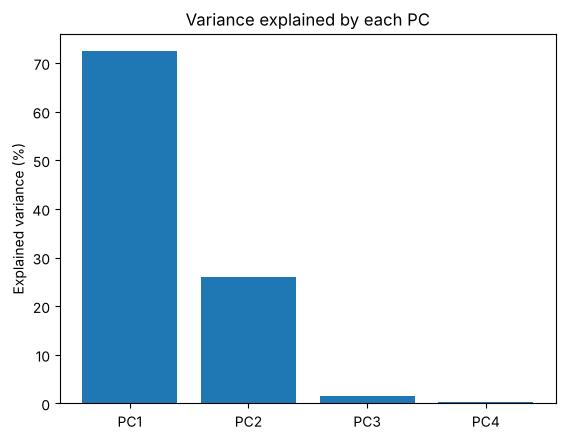

In [13]:
explained = eig_vals / eig_vals.sum() * 100
for i, e in enumerate(explained):
    print(f"PC{i+1} explains {e:.2f}% of the variance")
print(f"\nPC1 + PC2 together : {explained[:2].sum():.2f}%")

plt.bar(["PC1", "PC2", "PC3", "PC4"], explained)
plt.ylabel("Explained variance (%)")
plt.title("Variance explained by each PC")
plt.show()

### Step 5 : Project the data onto the top 2 PCs

In [14]:
W = eig_vecs[:, :2]               # 4 × 2
Z = X_std @ W                     # 10 × 2

pca_df = pd.DataFrame(Z, columns=["PC1", "PC2"]).round(3)
pca_df

,PC1,PC2
0,1.414,-0.334
1,-1.105,-0.549
2,-0.607,1.630
3,-0.097,-1.257
4,1.874,1.780
5,-3.378,-0.628
6,2.540,-1.132
7,1.155,-0.500
8,-0.179,0.227
9,-1.616,0.763


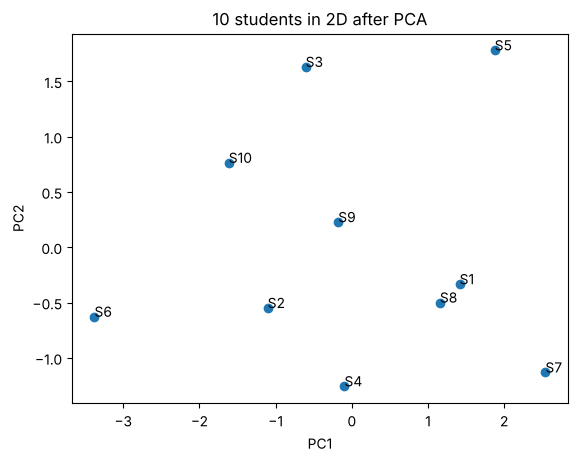

In [15]:
plt.scatter(pca_df["PC1"], pca_df["PC2"])
for i in range(n):
    plt.annotate(f"S{i+1}", (pca_df["PC1"][i], pca_df["PC2"][i]))
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("10 students in 2D after PCA")
plt.show()

### Checking with scikit-learn

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
Z_sk = pca.fit_transform(StandardScaler().fit_transform(X))

print("Explained variance ratio (sklearn) :", (pca.explained_variance_ratio_ * 100).round(2))
print("Same result as manual (ignoring sign) :", np.allclose(np.abs(Z), np.abs(Z_sk)))

Explained variance ratio (sklearn) : [72.37 25.94]
Same result as manual (ignoring sign) : True


### Result (Question 2)
* PCA was done step by step (standardise → covariance matrix → eigenvalues & eigenvectors → project) and matched scikit-learn's answer.
* The 4 attributes were reduced to 2 principal components that keep most of the information.
* PC1 captures most of the variance because study_hours, phone_hours and marks are strongly correlated (as found in Question 1).